[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AndresOrdonez369/deepLearningWeek1/blob/main/proyectos/NB02_sabado_tu_primera_red.ipynb)

# NB02 · Tu primera red: de la cuenta a mano a Keras
**Neural Networks: Deep Learning · UIDE · Semana 1 · Sábado** — Docente: Andrés Ordóñez-Bolaños

Hoy vas a ver **cómo aprende una red completa**. Primero hacemos a mano las cuentas de una red pequeñita (las mismas de las láminas), después conocemos **TensorFlow** y **Keras** desde cero y terminamos entrenando redes de verdad en pocas líneas, con gráficas de todo.

**La necesidad:** el viernes una sola neurona no pudo con XOR: solo sabe trazar **una línea**. La solución es **juntar neuronas en capas**. Pero entonces aparece la pregunta de hoy: si la red se equivoca, **¿a cuál de todos sus pesos le corregimos, y cuánto?**

### Cómo usar este Colab (2 minutos)
**Todo el código ya está escrito: tú lees, predices, ejecutas y comparas.** No tienes que programar nada para avanzar.

1. **Archivo → Guardar una copia en Drive.** Así tus cambios quedan guardados.
2. Ejecuta la celda **Configuración** (tarda unos segundos: carga TensorFlow). Después avanza en orden con `Shift + Enter`.
3. Cada parte sigue el mismo orden:
   **Qué vas a hacer → la necesidad → ejemplo → el nombre → la fórmula («Léelo así») → Qué hace este código → 🔮 Antes de ejecutar: ¿qué crees que saldrá? → ejecuta → Qué deberías ver → 💭 Para pensar.**
4. En **🔮 Antes de ejecutar** detente cinco segundos y apuesta un resultado. Acertar no importa; **comparar** sí.
5. En **💭 Para pensar** responde con tu pareja y después abre **Ver respuesta**.
6. Las celdas **🧪 Experimenta** son opcionales: cambia **un solo** valor marcado (por ejemplo `neuronas = 16   # try 4`) y vuelve a ejecutar.
7. **No tiene nota.** Trabajen en parejas y equivóquense sin miedo.

> **🛟 Si algo falla**
> - `NameError: name 'x' is not defined` → te saltaste una celda de arriba. Usa **Entorno de ejecución → Ejecutar anteriores** (o **Ejecutar todo**).
> - Un error que menciona `shape` (forma) o `Input 0 of layer ... is incompatible` → los datos no tienen la forma que la red espera (por ejemplo, 3 columnas para una red con `Input(shape=(2,))`). Vuelve a ejecutar la celda original sin cambios.
> - La pérdida sale `nan` o la exactitud se queda en 50 % → en un experimento el `learning_rate` quedó demasiado grande: vuelve al valor original.
> - Si cambiaste algo y ya no sabes qué: **Entorno de ejecución → Reiniciar y ejecutar todo**.

**La red de las cuentas a mano:** 2 entradas → 2 neuronas ocultas → 1 salida, todas con sigmoide.

### Mapa del Colab
| Parte | Qué aprendes | Lámina |
|---|---|---|
| 0 | NumPy exprés: vectores, matrices y una capa en una línea (si ya lo dominas, sáltala) | 47 |
| T | Conoce tus herramientas: qué son TensorFlow y Keras | 58, 66, 67 |
| A | Forward: la red predice | 53 |
| B | Backward: repartir la culpa | 54–56 |
| C | Un paso de aprendizaje | 57 |
| D | TensorFlow calcula lo mismo | 58 |
| E | Keras paso a paso: una capa oculta resuelve XOR | 48, 51, 68 |
| F | Keras completo con las lunas | 69, 71, 72, 73 |
| G | ¿Qué optimizador llega primero? | 63 |
| 🏁 | Resumen · **Para comprobar que entendiste** · **Experimento 2: los círculos** | 74 |

En clase (lámina 74): prioridad **A, B, E y F**. C, D y G pueden quedar para casa.

In [1]:
# @title Configuración · ejecuta esta celda primero (no necesitas abrirla)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow info messages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import tensorflow as tf
import keras
from keras import layers
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split

SEED = 2026
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

# The same colors as the slides: amber = yes / class 1, azure = no / class 0, mint = learned, coral = error
AMBAR, AZUL, MENTA, CORAL, TINTA, LILA = "#E39A12", "#2B8FD6", "#12A37F", "#E0533D", "#1F2A3A", "#8B6FD1"
MAPA = LinearSegmentedColormap.from_list("si_no", [AZUL, "#F4F7FA", AMBAR])

# Three new points the moons model never saw (used in "Para comprobar que entendiste")
NUEVOS = np.array([[0.0, 1.0], [1.0, -0.5], [0.5, 0.25]])

def plot_boundary(model, X, y, ax, title):
    # Shaded = probability of class 1 (amber) or class 0 (azure); black line = 50 %
    g1, g2 = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 200),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 200))
    P = model.predict(np.c_[g1.ravel(), g2.ravel()], verbose=0).reshape(g1.shape)
    ax.contourf(g1, g2, P, levels=np.linspace(0, 1, 11), cmap=MAPA, alpha=.75)
    ax.contour(g1, g2, P, levels=[.5], colors=TINTA, linewidths=2.5)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(np.asarray(y) == 1, AMBAR, AZUL), edgecolor=TINTA, s=30, lw=.5)
    ax.set_title(title)

def dibujar_red(W1, b1, W2, b2, x=None, a1=None, y_hat=None, title="", color_w=None):
    # A 2-2-1 network: edge color = sign (amber +, azure -), edge width = size of the weight
    P = {"x1": (0, .8), "x2": (0, .2), "h1": (1, .8), "h2": (1, .2), "o": (2, .5)}
    fig, ax = plt.subplots(figsize=(8, 4.2))
    edges = [("x1", "h1", W1[0, 0]), ("x2", "h1", W1[0, 1]), ("x1", "h2", W1[1, 0]), ("x2", "h2", W1[1, 1]),
             ("h1", "o", W2[0, 0]), ("h2", "o", W2[0, 1])]
    for a, b_, wv in edges:
        (xa, ya), (xb, yb) = P[a], P[b_]
        ax.plot([xa, xb], [ya, yb], color=color_w or (AMBAR if wv > 0 else AZUL), lw=1 + 4 * abs(wv), alpha=.85, zorder=1)
        t = .3; ax.text(xa + (xb - xa) * t, ya + (yb - ya) * t + .045, f"{wv:+.2f}", ha="center", fontsize=10,
                        color=TINTA, bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none"))
    vals = {"x1": None if x is None else x[0], "x2": None if x is None else x[1],
            "h1": None if a1 is None else a1[0], "h2": None if a1 is None else a1[1], "o": None if y_hat is None else float(np.ravel(y_hat)[0])}
    bias = {"h1": b1[0], "h2": b1[1], "o": float(np.ravel(b2)[0])}
    for k, (xp, yp) in P.items():
        ax.scatter(xp, yp, s=1700, color="white", edgecolor=TINTA, lw=2, zorder=2)
        ax.text(xp, yp, "" if vals[k] is None else f"{vals[k]:.2f}", ha="center", va="center", fontsize=12, weight="bold", zorder=3)
        if k in bias:
            ax.text(xp, yp + .15, f"b = {bias[k]:+.2f}", ha="center", fontsize=9, color="gray")
    for k, lab in [("x1", "antigüedad"), ("x2", "carga de la cuota"), ("h1", "oculta 1"), ("h2", "oculta 2"), ("o", "salida ŷ")]:
        ax.text(P[k][0], P[k][1] - .17, lab, ha="center", fontsize=9, color="gray")
    ax.set_xlim(-.4, 2.4); ax.set_ylim(-.05, 1.08); ax.axis("off"); ax.set_title(title)
    plt.show()

print("Listo. TensorFlow", tf.__version__, "| Keras", keras.__version__)

Listo. TensorFlow 2.21.0 | Keras 3.15.1


---
## 0 · NumPy exprés para redes (si ya lo dominas, sáltala)
📽 Lámina 47

**Qué vas a hacer:** escribir **una capa entera de neuronas en una sola línea** de NumPy.

**La idea:** el viernes una neurona hacía $z = \mathbf{w}\cdot\mathbf{x} + b$. Una **capa** son varias neuronas que miran los mismos datos. Si ponemos los pesos de cada neurona en una **fila** de una matriz $W$, toda la capa es:

$$\mathbf{z} = W\mathbf{x} + \mathbf{b} \qquad\qquad \mathbf{a} = \sigma(\mathbf{z})$$

**Léelo así:** "cada fila de $W$ (una neurona) multiplica a $\mathbf{x}$ y suma; a cada resultado le sumamos su sesgo; y la sigmoide se aplica a cada número por separado". En NumPy: `W @ x + b`.

**Qué hace este código:**
- `x` es **un ejemplo** (un socio) con 2 datos: forma `(2,)`.
- `W` tiene **una fila por neurona** y una columna por dato: forma `(2, 2)` = 2 neuronas × 2 datos.
- `b` tiene un sesgo por neurona.
- `W @ x` hace el producto punto de **cada fila** con `x`: cada neurona hace su suma ponderada.

🔮 **Antes de ejecutar:** calcula a mano la primera neurona: 0.5·1.0 − 0.3·0.5 = ?

In [2]:
x = np.array([1.0, 0.5])               # one member: 2 features  -> shape (2,)
W = np.array([[0.5, -0.3],             # row 0: weights of hidden neuron 1
              [0.2,  0.8]])            # row 1: weights of hidden neuron 2  -> shape (2, 2)
b = np.array([0.1, -0.1])              # one bias per neuron

print("forma de x:", x.shape, "| forma de W:", W.shape, "| forma de b:", b.shape)
print("Fila 0 de W (neurona 1):", W[0], "| fila 1 (neurona 2):", W[1])
print("W @ x =", W @ x, " ← cada neurona hace su suma ponderada")

forma de x: (2,) | forma de W: (2, 2) | forma de b: (2,)
Fila 0 de W (neurona 1): [ 0.5 -0.3] | fila 1 (neurona 2): [0.2 0.8]
W @ x = [0.35 0.6 ]  ← cada neurona hace su suma ponderada


**Qué deberías ver:** formas `(2,)`, `(2, 2)` y `(2,)`, y `W @ x = [0.35 0.6]`: la neurona 1 da 0.5·1.0 − 0.3·0.5 = 0.35 y la neurona 2, 0.2·1.0 + 0.8·0.5 = 0.6.

### Una capa completa en dos líneas
**Qué hace este código:**
- `z_capa = W @ x + b` suma a cada neurona su sesgo: los **puntajes** de la capa.
- `sigmoid(z_capa)` aplica la sigmoide **a cada número por separado**: las **salidas** de la capa (se llaman *activaciones*, `a`).

🔮 **Antes de ejecutar:** los puntajes serán 0.35 + 0.1 y 0.6 − 0.1. ¿Las salidas quedarán por encima o por debajo de 0.5?

In [3]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))    # works on whole arrays, number by number
z_capa = W @ x + b                          # scores of the 2 neurons
a_capa = sigmoid(z_capa)                    # outputs (activations) of the 2 neurons
print("z =", z_capa, "| a =", a_capa)

z = [0.45 0.5 ] | a = [0.6106 0.6225]


**Qué deberías ver:** `z = [0.45 0.5 ]` y `a = [0.6106 0.6225]`: dos neuronas calculadas en una línea. Guárdalo: es la capa oculta de la Parte A.

### 💭 Para pensar

**1.** Si la capa tuviera 16 neuronas en vez de 2 (y los mismos 2 datos), ¿qué forma tendría `W`? ¿Y `W @ x`?

<details><summary>Ver respuesta</summary>

`W` sería `(16, 2)`: una fila por neurona. `W @ x` devolvería 16 números, uno por neurona.
</details>

**2.** ¿Por qué $z$ es positivo y aun así las salidas son solo ≈ 0.61, no cercanas a 1?

<details><summary>Ver respuesta</summary>

Porque la sigmoide de un número pequeño (0.45 o 0.5) queda poco por encima de 0.5. Solo con $z$ grandes se acerca a 1.
</details>

---
## T · Conoce tus herramientas: TensorFlow y Keras
📽 Láminas 66–67

**Qué vas a hacer:** entender qué son las dos librerías que usa todo el curso, cómo se importan y en qué se diferencian de NumPy.

**TensorFlow** es la librería de Google para hacer las cuentas de las redes neuronales (la publicó como código abierto en noviembre de 2015). Sabe hacer dos cosas que NumPy no hace solo: **calcular derivadas automáticamente** y repartir el trabajo en **CPU o GPU**.

**Keras** es la librería que te deja **armar y entrenar redes en pocas líneas** (la creó François Chollet en marzo de 2015; hoy es Keras 3). Por dentro usa a TensorFlow.

> **Analogía:** TensorFlow es **el motor**; Keras es **el volante y los pedales**. Puedes manejar sin abrir el capó, pero ayuda saber que el motor existe.

| Capa | Qué hace | En este curso |
|---|---|---|
| Tú (Python) | escribes qué quieres | celdas de Colab |
| **Keras** | piezas listas: capas, pérdidas, optimizadores, `fit` | Partes E, F, G |
| **TensorFlow** | tensores, derivadas automáticas, CPU/GPU | Parte D |
| Hardware | hace las multiplicaciones | la CPU o GPU de Colab |

En Colab ya vienen instaladas: solo hay que **importarlas**.

**Qué hace este código:**
- `import tensorflow as tf` carga TensorFlow con su apodo de siempre, `tf`.
- `from keras import layers` trae las piezas para armar capas; así luego escribimos `layers.Dense(...)`.
- La última línea pregunta si hay **GPU** (tarjeta gráfica). Para esta clase la CPU basta.

In [4]:
import tensorflow as tf          # "tf" is the standard nickname
import keras                     # Keras 3
from keras import layers         # the building blocks (Dense, ...) -> we will write layers.Dense

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU") or "no (CPU basta para esta clase)")

TensorFlow 2.21.0 | Keras 3.15.1
GPU disponible: no (CPU basta para esta clase)


### Tensores: los arrays de TensorFlow
Un **tensor** es como un array de NumPy (un bloque de números con forma), pero vive en TensorFlow y puede ir a la GPU. Una `tf.Variable` es un tensor que **puede cambiar**: así se guardan los pesos que la red aprende.

**Qué hace este código:**
- `tf.constant(...)` crea un tensor fijo de 2 × 2.
- `t @ t` multiplica matrices igual que en NumPy; `.numpy()` lo convierte de vuelta a un array de NumPy para imprimirlo bonito.
- `tf.Variable(0.7)` crea un peso que se puede cambiar; `.assign(0.84)` le pone un valor nuevo, como hará el entrenamiento.

In [5]:
t = tf.constant([[1.0, 2.0],
                 [3.0, 4.0]])               # a 2x2 tensor
print("tensor:\n", t)
print("forma:", t.shape, "| tipo:", t.dtype)
print("t @ t =\n", (t @ t).numpy())          # same matrix product as NumPy; .numpy() converts back

peso = tf.Variable(0.7)                      # a trainable number (a weight)
peso.assign(0.84)                            # training changes it like this
print("peso después de un paso:", peso.numpy())

tensor:
 tf.Tensor(
[[1. 2.]
 [3. 4.]], shape=(2, 2), dtype=float32)
forma: (2, 2) | tipo: <dtype: 'float32'>
t @ t =
 [[ 7. 10.]
 [15. 22.]]
peso después de un paso: 0.84


**Qué deberías ver:** la forma `(2, 2)`, el producto `[[7. 10.] [15. 22.]]` (igual que en NumPy) y el peso que pasa de 0.7 a 0.84, como en la lámina 57.

<details><summary>Para curiosos: Keras 3 tiene varios motores</summary>

Keras 3 puede usar como motor a TensorFlow, a JAX o a PyTorch. En Colab, por defecto, usa TensorFlow. El código de Keras que escribas hoy funciona igual con cualquiera.
</details>

---
## Parte A · Forward: la información viaja hacia adelante
📽 Lámina 53

**Qué vas a hacer:** calcular a mano la predicción de una red 2 → 2 → 1.

**La idea:** cada capa hace lo de la Parte 0; la salida de una capa es la entrada de la siguiente:

$$\mathbf{a}^{(1)} = \sigma\big(W^{(1)}\mathbf{x} + \mathbf{b}^{(1)}\big) \qquad\qquad \hat y = \sigma\big(W^{(2)}\mathbf{a}^{(1)} + b^{(2)}\big)$$

**Léelo así:** "la capa oculta ($\mathbf{a}^{(1)}$) es la sigmoide de sus pesos por los datos más sus sesgos; la predicción ($\hat y$, *y gorro*) es la sigmoide de los pesos de salida por lo que produjo la capa oculta, más su sesgo". El número entre paréntesis arriba solo dice de qué capa es.

### Ejemplo: el socio 1
$x_1$ = antigüedad (1.0), $x_2$ = carga de la cuota (0.5), ambas escaladas. **La verdad:** $y = 1$ (sí pagó).

| Capa | Pesos | Sesgos |
|---|---|---|
| Oculta | neurona 1: (0.5, −0.3) · neurona 2: (0.2, 0.8) | 0.1 · −0.1 |
| Salida | (0.7, −0.4) | 0.05 |

**Qué hace este código:**
- `W1`, `b1` son los pesos y sesgos de la capa oculta (una fila por neurona); `W2`, `b2` los de la salida.
- `a1 = sigmoid(W1 @ x + b1)` es la capa oculta (lo mismo de la Parte 0).
- `y_hat = sigmoid(W2 @ a1 + b2)`: **lo que salió de la capa oculta entra a la salida**.
- `loss = -np.log(y_hat)` es la BCE del viernes para $y = 1$: menos el logaritmo de la probabilidad que le dio a lo que pasó.

🔮 **Antes de ejecutar:** la red es nueva (pesos sin entrenar). ¿Crees que estará segura de que el socio paga (cerca de 1) o dudando (cerca de 0.5)?

In [6]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))

x  = np.array([1.0, 0.5]); y = 1.0       # member 1 and the truth (paid)
W1 = np.array([[0.5, -0.3],              # hidden neuron 1
               [0.2,  0.8]])             # hidden neuron 2
b1 = np.array([0.1, -0.1])
W2 = np.array([[0.7, -0.4]])             # output neuron
b2 = np.array([0.05])

z1 = W1 @ x + b1;  a1 = sigmoid(z1)       # hidden layer
z2 = W2 @ a1 + b2; y_hat = sigmoid(z2)    # output layer
loss = -np.log(y_hat)                     # cross-entropy (BCE) for y = 1

print("Capa oculta:  z =", z1, " -> a =", a1)
print("Salida:       z =", z2, " -> ŷ =", y_hat)
print("Pérdida:      -log(ŷ) =", loss)

Capa oculta:  z = [0.45 0.5 ]  -> a = [0.6106 0.6225]
Salida:       z = [0.2285]  -> ŷ = [0.5569]
Pérdida:      -log(ŷ) = [0.5854]


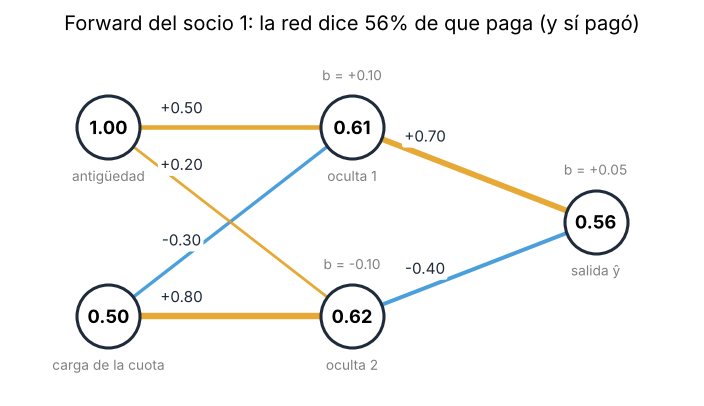

In [7]:
dibujar_red(W1, b1, W2, b2, x=x, a1=a1, y_hat=y_hat,
            title=f"Forward del socio 1: la red dice {y_hat[0]:.0%} de que paga (y sí pagó)")

**Qué deberías ver:** capa oculta a = (0.6106, 0.6225); predicción **ŷ = 0.5569** (56 % de que paga); pérdida **0.5854 ≈ 0.59**. En el dibujo, el grosor de cada cable es el tamaño del peso (ámbar positivo, azul negativo) y dentro de cada neurona está lo que produce.

### Otro ejemplo: el socio 2, hacia adelante
El **socio 2** tiene antigüedad 0.2 y carga de cuota 1.0, y **no pagó** ($y = 0$). Usamos la **misma red**.

**Qué hace este código:** las mismas dos líneas del forward con `x_2`. Cambia solo la pérdida: como $y = 0$, la BCE es $-\log(1-\hat y)$ (menos el logaritmo de la probabilidad que le dio a "no paga").

🔮 **Antes de ejecutar:** este socio tiene poca antigüedad y una cuota pesada. ¿La red le dará más o menos probabilidad de pago que al socio 1?

In [8]:
x_2 = np.array([0.2, 1.0]); y_2 = 0.0             # member 2 did NOT pay
a1_2 = sigmoid(W1 @ x_2 + b1)                     # hidden layer
y_hat_2 = sigmoid(W2 @ a1_2 + b2)                 # output: probability of paying
loss_2 = -np.log(1 - y_hat_2)                     # BCE for y = 0
print("a1 =", a1_2, "| ŷ =", y_hat_2, "| pérdida =", loss_2)

a1 = [0.475 0.677] | ŷ = [0.5279] | pérdida = [0.7506]


**Qué deberías ver:** a1 ≈ (0.4750, 0.6770), **ŷ ≈ 0.5279** (le da 53 % a alguien que no pagó) y pérdida ≈ **0.7506**. Casi lo mismo que al socio 1: una red sin entrenar **todavía no distingue** a los socios.

### 💭 Para pensar

**1.** ¿Por qué al socio 1 la pérdida es $-\log(\hat y)$ y al socio 2 es $-\log(1-\hat y)$?

<details><summary>Ver respuesta</summary>

Porque la BCE mira la probabilidad que el modelo le dio **a lo que de verdad pasó**: el socio 1 pagó (probabilidad $\hat y$), el socio 2 no pagó (probabilidad $1-\hat y$).
</details>

**2.** ¿Qué entra a la neurona de salida: los datos del socio o lo que produjo la capa oculta?

<details><summary>Ver respuesta</summary>

Lo que produjo la capa oculta ($\mathbf{a}^{(1)}$). Cada capa recibe la salida de la anterior: por eso se dice que la información viaja **hacia adelante**.
</details>

---
## Parte B · Backward: la culpa viaja hacia atrás
📽 Láminas 54–56

**Qué vas a hacer:** calcular cuánta "culpa" del error le toca a cada peso.

**La necesidad:** la red tiene 9 números (6 pesos y 3 sesgos). La pérdida nos dice **qué tan mal** fue, pero no **a quién corregir**. Necesitamos la derivada de la pérdida respecto a **cada uno** de los 9 números: el **gradiente** (la lista de derivadas del viernes).

**La idea:** como en la **cadena del cacao**: el cliente prueba la barra de chocolate y dice "salió amarga" (el error se descubre al final). La culpa se reparte hacia atrás: el tostado recibe culpa según cuánto influyó, y la pasa al fermentado y a la cosecha. Los efectos se multiplican a lo largo de la cadena, como **engranajes**.

**El nombre:** repartir así las derivadas desde la salida hacia atrás se llama **retropropagación** (*backpropagation*), y la multiplicación de efectos es la **regla de la cadena**.

> **«Culpa» es una metáfora.** Cuando decimos "la culpa de una neurona" ($\delta$, se lee *delta*) queremos decir **la derivada de la pérdida respecto al puntaje $z$ de esa neurona**: cuánto cambiaría la pérdida si ese $z$ subiera un poquito. Nadie "tiene la culpa" de verdad; es solo una forma de recordar que la corrección se reparte.

Tres reglas bastan:

1. **Culpa de la salida:** $\delta^{(2)} = \hat y - y$. *Léelo así:* predicción menos etiqueta (lo que dijo menos lo que era). Para el socio 1: $0.5569 - 1 = -0.4431$. Negativa = se quedó corta, hay que **subir** la predicción.
2. **Culpa de una neurona oculta:** la culpa que le llega por su cable (peso × culpa de la salida) **por** la pendiente de su sigmoide, $\sigma'(z) = a(1-a)$.
3. **Gradiente de un peso:** la culpa de su neurona **por** lo que entró por ese cable.

### Ejemplo: el socio 1
**Qué hace este código, línea por línea:**
- `d2 = y_hat - y` → regla 1.
- `np.outer(d2, a1)` → regla 3 para los 2 pesos de la salida: la culpa de la salida por cada valor que entró desde la capa oculta. El gradiente de un sesgo es la culpa sola (por su "cable" siempre entra un 1).
- `(W2.T @ d2) * a1 * (1 - a1)` → regla 2: `W2.T @ d2` manda la culpa hacia atrás por cada cable (peso × culpa) y `a1 * (1 - a1)` es la pendiente de cada sigmoide.
- `np.outer(d1, x)` → regla 3 para los 4 pesos de la capa oculta.

🔮 **Antes de ejecutar:** ¿la culpa de la capa oculta será más grande o más pequeña que la de la salida (−0.44)?

In [9]:
d2  = y_hat - y                       # rule 1: output blame
dW2 = np.outer(d2, a1); db2 = d2      # rule 3 for the output layer (blame x what came in)

d1  = (W2.T @ d2) * a1 * (1 - a1)     # rule 2: blame sent back through each wire, times sigmoid slope
dW1 = np.outer(d1, x);  db1 = d1      # rule 3 for the hidden layer

print("Culpa de la salida   δ2 =", d2)
print("Gradiente de W2      =", dW2)
print("Culpa capa oculta    δ1 =", d1)
print("Gradiente de W1      =\n", dW1)

Culpa de la salida   δ2 = [-0.4431]
Gradiente de W2      = [[-0.2706 -0.2758]]
Culpa capa oculta    δ1 = [-0.0738  0.0417]
Gradiente de W1      =
 [[-0.0738 -0.0369]
 [ 0.0417  0.0208]]


**Qué deberías ver:** δ2 = **−0.4431** (la predicción se quedó corta: dijo 0.56 y era 1); gradiente de W2 = (**−0.2706**, **−0.2758**); δ1 = (**−0.0738**, **+0.0417**).
La culpa de la capa oculta es mucho más pequeña: la pendiente de la sigmoide (≈ 0.24) la encoge al pasar hacia atrás. Y la oculta 2 recibe culpa **positiva**: su peso hacia la salida es negativo, así que para que la salida suba, ella debe bajar.

### Otro ejemplo: la culpa del socio 2
**Qué hace este código:** las mismas tres reglas con los resultados del socio 2 (que **no** pagó, $y = 0$).

🔮 **Antes de ejecutar:** la red le dio 0.53 a alguien que no pagó. ¿La culpa de la salida será positiva o negativa? ¿Qué significa?

In [10]:
d2_2 = y_hat_2 - y_2                               # rule 1: prediction minus label
dW2_2 = np.outer(d2_2, a1_2)                       # rule 3, output layer
d1_2 = (W2.T @ d2_2) * a1_2 * (1 - a1_2)           # rule 2, hidden layer
dW1_2 = np.outer(d1_2, x_2)                        # rule 3, hidden layer
print("δ2 =", d2_2, "| dW2 =", dW2_2)
print("δ1 =", d1_2)

δ2 = [0.5279] | dW2 = [[0.2508 0.3574]]
δ1 = [ 0.0922 -0.0462]


**Qué deberías ver:** δ2 = **+0.5279** (0.5279 − 0), dW2 ≈ (0.2508, 0.3574) y δ1 ≈ (+0.0922, −0.0462). La culpa es **positiva**: la red debe **bajar** su predicción para este socio, al revés que con el socio 1.

### 💭 Para pensar

**1.** ¿Qué quiere decir que la culpa de la salida del socio 1 sea −0.4431?

<details><summary>Ver respuesta</summary>

Que la predicción (0.5569) quedó **por debajo** de la etiqueta (1): la derivada es negativa, así que hay que **subir** la predicción.
</details>

**2.** ¿Por qué la culpa de la capa oculta es mucho más pequeña que la de la salida?

<details><summary>Ver respuesta</summary>

Porque al pasar hacia atrás se multiplica por el peso del cable y por la pendiente de la sigmoide, $a(1-a)$, que nunca pasa de 0.25. Por eso las capas del fondo aprenden más despacio.
</details>

**3.** ¿La «culpa» es algo que la red siente?

<details><summary>Ver respuesta</summary>

No: es una metáfora para la **derivada** de la pérdida respecto al puntaje de cada neurona.
</details>

---
## Parte C · Un paso de aprendizaje y su verificación
📽 Lámina 57

**Qué vas a hacer:** mover los 9 números de la red un pasito cuesta abajo y comprobar que la predicción mejora.

**La idea:** es el descenso de gradiente del viernes (el **Cotopaxi**), con todos los pesos a la vez:

$$w \leftarrow w - \eta \cdot \text{gradiente}$$

**Léelo así:** "a cada peso le restamos η por su culpa". Con η = 0.5, el peso 0.7 de la oculta 1 a la salida queda en $0.7 - 0.5\times(-0.27) = 0.84$.

### Ejemplo: el socio 1, con η = 0.5
**Qué hace este código:**
- `W1 - eta * dW1` (y lo mismo con `b1`, `W2`, `b2`) mueve **cada** número en contra de su gradiente: los 9 a la vez.
- Después repite el forward con los números nuevos (`W1n`, `b1n`, …) para ver si la predicción mejoró.

🔮 **Antes de ejecutar:** el socio 1 sí pagó y la red dijo 0.56. Después del paso, ¿la predicción sube o baja? ¿Y la pérdida?

In [11]:
eta = 0.5
W1n, b1n = W1 - eta * dW1, b1 - eta * db1     # every piece moves against its gradient
W2n, b2n = W2 - eta * dW2, b2 - eta * db2
a1n = sigmoid(W1n @ x + b1n)
y_hat_new = sigmoid(W2n @ a1n + b2n)
print("Peso oculta 1 → salida:", W2[0, 0], "->", round(W2n[0, 0], 4))
print(f"Predicción: {y_hat[0]:.4f} -> {y_hat_new[0]:.4f}")
print(f"Pérdida:    {loss[0]:.4f} -> {-np.log(y_hat_new[0]):.4f}")

Peso oculta 1 → salida: 0.7 -> 0.8353
Predicción: 0.5569 -> 0.6542
Pérdida:    0.5854 -> 0.4243


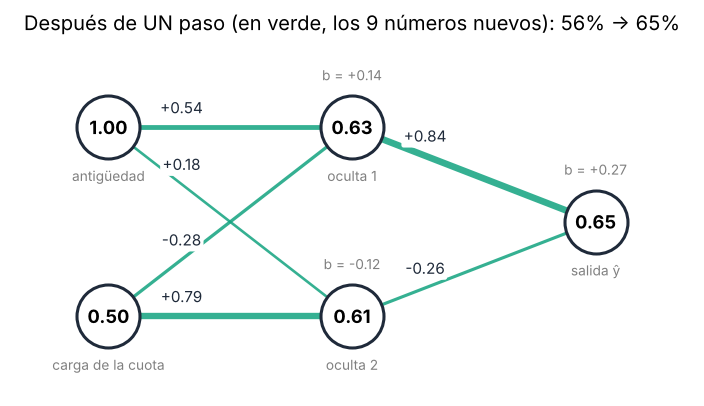

In [12]:
dibujar_red(W1n, b1n, W2n, b2n, x=x, a1=a1n, y_hat=y_hat_new, color_w=MENTA,
            title=f"Después de UN paso (en verde, los 9 números nuevos): {y_hat[0]:.0%} → {y_hat_new[0]:.0%}")

**Qué deberías ver:** el peso 0.7 pasa a **0.8353 ≈ 0.84**; la predicción 0.5569 → **0.6542** (56 % → 65 %) y la pérdida 0.5854 → **0.4243** (0.59 → 0.42).

<details><summary>Para curiosos: ¿cómo sabemos que las culpas están bien? (gradient check)</summary>

Movemos cada peso un poquito ($10^{-5}$) hacia arriba y hacia abajo, medimos cuánto cambia la pérdida y comparamos con nuestras culpas. Si coinciden, las cuentas están bien.

```python
def loss_of(params):
    W1_, b1_, W2_, b2_ = params[:4].reshape(2, 2), params[4:6], params[6:8].reshape(1, 2), params[8:]
    return float(-np.log(sigmoid(W2_ @ sigmoid(W1_ @ x + b1_) + b2_)[0]))
p0 = np.concatenate([W1.ravel(), b1, W2.ravel(), b2])
g_backprop = np.concatenate([dW1.ravel(), db1, dW2.ravel(), db2])
g_numeric = np.array([(loss_of(p0 + 1e-5 * e) - loss_of(p0 - 1e-5 * e)) / 2e-5 for e in np.eye(len(p0))])
print(np.linalg.norm(g_numeric - g_backprop) / np.linalg.norm(g_numeric + g_backprop))   # ~1e-11
```
</details>

### Otro ejemplo: un paso con el socio 2
**Qué hace este código:** el mismo paso con los gradientes del socio 2 (partiendo otra vez de los pesos **originales**) y un forward con los pesos nuevos.

🔮 **Antes de ejecutar:** este socio **no** pagó y la red dijo 0.53. ¿Qué debería pasar con su predicción?

In [13]:
W1_2n, b1_2n = W1 - eta * dW1_2, b1 - eta * d1_2   # the bias gradient is the blame itself
W2_2n, b2_2n = W2 - eta * dW2_2, b2 - eta * d2_2
y_hat_2_nuevo = sigmoid(W2_2n @ sigmoid(W1_2n @ x_2 + b1_2n) + b2_2n)
print(f"ŷ del socio 2: {y_hat_2[0]:.4f} -> {y_hat_2_nuevo[0]:.4f}")
print(f"Pérdida:       {loss_2[0]:.4f} -> {-np.log(1 - y_hat_2_nuevo[0]):.4f}")

ŷ del socio 2: 0.5279 -> 0.4129
Pérdida:       0.7506 -> 0.5325


**Qué deberías ver:** ŷ 0.5279 → **0.4129** y la pérdida 0.7506 → **0.5325**. La predicción **bajó**, como debía: ahora la red duda más de que este socio pague.

### 💭 Para pensar

**1.** En un paso, ¿cuántos números de la red cambiaron?

<details><summary>Ver respuesta</summary>

Los **9**: 6 pesos y 3 sesgos, cada uno según su propia derivada.
</details>

**2.** Con el socio 1 la predicción subió y con el socio 2 bajó, usando la misma fórmula. ¿Qué lo decidió?

<details><summary>Ver respuesta</summary>

El **signo de la culpa** de la salida: −0.44 (se quedó corta → subir) para el socio 1, +0.53 (se pasó → bajar) para el socio 2.
</details>

**3.** ¿Qué hace `fit` en Keras, comparado con esta parte?

<details><summary>Ver respuesta</summary>

Exactamente esto (forward → pérdida → backward → un paso), pero con muchos socios y miles de veces.
</details>

---
## Parte D · TensorFlow hace la cuenta por ti
📽 Lámina 58

**Qué vas a hacer:** pedirle a TensorFlow las mismas culpas de la Parte B, sin escribir ninguna regla.

**La idea:** `tf.GradientTape` funciona como una **grabadora**: graba cada operación de la ida (forward) y después la reproduce al revés aplicando la regla de la cadena. Esto se llama **diferenciación automática** y es como entrena cualquier red de verdad.

### Ejemplo: los mismos gradientes del socio 1
**Qué hace este código:**
- `tf.Variable(v)` convierte cada pieza de la red en un número que TensorFlow puede derivar.
- Todo lo que está **dentro** de `with tf.GradientTape() as tape:` queda grabado: es el mismo forward de la Parte A, escrito con funciones de TensorFlow.
- `tape.gradient(t_loss, [...])` reproduce la grabación al revés y devuelve las derivadas de la pérdida respecto a cada pieza.
- La última línea compara con nuestras cuentas a mano de la Parte B.

🔮 **Antes de ejecutar:** ¿cuánto crees que será la diferencia entre TensorFlow y nuestra cuenta?

In [14]:
# The same weights, now as TensorFlow Variables (numbers TF is allowed to change)
tW1, tb1, tW2, tb2 = [tf.Variable(v) for v in (W1, b1, W2, b2)]

with tf.GradientTape() as tape:                         # 1) press REC: record the forward pass
    t_hidden = tf.sigmoid(tf.linalg.matvec(tW1, tf.constant(x)) + tb1)
    t_yhat = tf.sigmoid(tf.linalg.matvec(tW2, t_hidden) + tb2)
    t_loss = -tf.math.log(t_yhat[0])

gW1, gb1, gW2, gb2 = tape.gradient(t_loss, [tW1, tb1, tW2, tb2])   # 2) play it backwards

print("Gradiente de W1 según TensorFlow:\n", gW1.numpy())
diff = max(np.abs(gW1.numpy() - dW1).max(), np.abs(gW2.numpy() - dW2).max())
print("Diferencia máxima con nuestra cuenta a mano:", diff)

Gradiente de W1 según TensorFlow:
 [[-0.0738 -0.0369]
 [ 0.0417  0.0208]]
Diferencia máxima con nuestra cuenta a mano: 5.551115123125783e-17


**Qué deberías ver:** la misma matriz de la Parte B y una diferencia del orden de **1e-17**: cero en la práctica (son errores de redondeo).

### Ejemplo: los engranajes en TensorFlow
En las láminas vimos $z = (3x)^2$: el engranaje de adentro multiplica por 3 y el de afuera, en $x = 1$, por 6 (la derivada de $u^2$ es $2u$, y $u = 3$). Juntos: $3 \times 6 = 18$.

**Qué hace este código:** graba $z = (3x)^2$ con `x = 1` y le pide a TensorFlow la derivada $\dfrac{dz}{dx}$.

🔮 **Antes de ejecutar:** ¿qué número debería salir?

In [15]:
xv = tf.Variable(1.0)                     # the input, as a variable TF can differentiate
with tf.GradientTape() as tape:           # record...
    zv = (3 * xv) ** 2                    # inner gear x3, outer gear squares
grad_engranajes = float(tape.gradient(zv, xv))   # ...and play backwards
print("dz/dx en x = 1:", grad_engranajes)

dz/dx en x = 1: 18.0


**Qué deberías ver:** `dz/dx en x = 1: 18.0` = 3 × 6. TensorFlow aplicó la regla de la cadena, como los engranajes.

🧪 **Experimenta:** cambia `(3 * xv) ** 2` por `(5 * xv) ** 2`. ¿Qué número esperas antes de ejecutar? (Adentro ×5, afuera 2·5 = 10.)

### 💭 Para pensar

**1.** ¿Qué graba exactamente `GradientTape`?

<details><summary>Ver respuesta</summary>

Cada operación del forward que ocurre **dentro** del bloque `with`. Con esa grabación puede aplicar la regla de la cadena hacia atrás.
</details>

**2.** ¿Por qué la diferencia con la cuenta a mano no es exactamente 0?

<details><summary>Ver respuesta</summary>

Por **redondeo**: las computadoras guardan los decimales con precisión limitada. 1e-17 es cero en la práctica.
</details>

---
## Parte E · Keras paso a paso: una capa oculta resuelve XOR
📽 Láminas 48, 51, 68

**Qué vas a hacer:** construir tu primera red con Keras, línea por línea, y resolver la **luz de la escalera** (XOR) que el viernes venció al perceptrón.

**La idea:** con Keras armas una red como un **LEGO**: apilas capas, una sobre otra, dentro de `keras.Sequential`. Siempre son tres pasos: **construir → compilar → entrenar**, y después **predecir**.

### E.1 · Los datos
Los datos entran como **arrays de NumPy**: `X` es una tabla (una fila por ejemplo, una columna por dato) e `y` es la respuesta de cada fila.

In [16]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)   # 4 examples x 2 switches
y_xor = np.array([0, 1, 1, 0], float)                       # light on (1) only if the switches differ
print("X:", X_xor.shape, "→ 4 ejemplos, 2 datos cada uno | y:", y_xor.shape)

X: (4, 2) → 4 ejemplos, 2 datos cada uno | y: (4,)


### E.2 · Construir: apilar las capas
- `keras.Sequential([...])` → una red donde la información pasa por las capas **en orden**.
- `keras.Input(shape=(2,))` → la puerta de entrada: cada ejemplo trae **2 números**. No calcula nada.
- `layers.Dense(8, activation="tanh")` → una capa **densa** de **8 neuronas**: cada una conectada con todas las entradas, como la neurona del viernes. `activation` es la función que dobla la línea (`"relu"`, `"tanh"`, `"sigmoid"`…).
- **tanh** (tangente hiperbólica) es prima de la sigmoide: la misma forma de S, pero su salida va de **−1 a 1** en vez de 0 a 1, centrada en 0. Funciona bien en capas ocultas pequeñas como esta.
- `layers.Dense(1, activation="sigmoid")` → la salida: **una** neurona con sigmoide, que da una **probabilidad** entre 0 y 1.
- `keras.utils.set_random_seed(SEED)` → los pesos **empiezan al azar**; fijar la semilla hace que todos tengamos el mismo azar y los mismos resultados.

🔮 **Antes de ejecutar:** ¿cuántos números (pesos + sesgos) tendrá que aprender esta red? Cuenta: 2 entradas → 8 neuronas → 1 salida.

In [17]:
keras.utils.set_random_seed(SEED)           # same starting weights for everyone

xor_net = keras.Sequential([
    keras.Input(shape=(2,)),                # 2 inputs: the two switches
    layers.Dense(8, activation="tanh"),     # hidden layer: 8 neurons
    layers.Dense(1, activation="sigmoid"),  # output: probability that the light is on
])
xor_net.summary()                           # a table of the layers and how many numbers each one learns

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33 (132.00 B)

 Trainable params: 33 (132.00 B)

 Non-trainable params: 0 (0.00 B)

**Léelo así (la tabla de `summary`):** la capa oculta aprende $2 \times 8 + 8 = 24$ números (un peso por cada cable y un sesgo por neurona) y la salida $8 \times 1 + 1 = 9$. Total: **33 parámetros**, las "perillas" de esta consola de sonido.

> **Parámetros vs. hiperparámetros.** Los **parámetros** son los números que la red **aprende sola** (pesos y sesgos: aquí, 33). Los **hiperparámetros** son las decisiones que tomas **tú** antes de entrenar: cuántas capas, cuántas neuronas (8), qué activación (tanh), el `learning_rate`, las épocas, el `batch_size`. La red no los cambia.

### E.3 · Compilar: las reglas del entrenamiento
`compile` no entrena todavía: **configura** cómo se va a entrenar.
- `optimizer` → **cómo** se dan los pasos cuesta abajo. `keras.optimizers.Adam(0.05)` es Adam con `learning_rate` (η) = 0.05.
- `loss` → **qué** se mide para saber qué tan mal vamos: `"binary_crossentropy"` es la BCE del viernes (para sí/no).
- `metrics` → qué más queremos ver mientras entrena (no se usa para aprender): `"accuracy"` = % de aciertos.

In [18]:
xor_net.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05),
                loss="binary_crossentropy",
                metrics=["accuracy"])

### E.4 · Entrenar: `fit`
`fit` hace **todo lo de las Partes A a C**, miles de veces: adelante → pérdida → atrás → un paso.
- `epochs=500` → 500 vueltas completas por los datos.
- `batch_size=4` → cuántos ejemplos mira antes de dar cada paso (aquí, los 4 a la vez).
- `verbose=0` → que no imprima cada época (usa `1` si quieres verlas).

Devuelve un objeto **History** con la pérdida de cada época.

🔮 **Antes de ejecutar:** sin entrenar, la red duda en todo (≈ 0.5). ¿Cuánto vale $-\log(0.5)$, la pérdida de partida aproximada?

In [19]:
hist_xor = xor_net.fit(X_xor, y_xor, epochs=500, batch_size=4, verbose=0)
print(f"Pérdida: época 1 = {hist_xor.history['loss'][0]:.3f}  →  época 500 = {hist_xor.history['loss'][-1]:.3f}")

Pérdida: época 1 = 0.777  →  época 500 = 0.000


### E.5 · Predecir: de probabilidad a decisión
`predict` devuelve la **probabilidad** de clase 1 para cada fila. Para decidir, usamos un umbral: **≥ 0.5 → 1**, si no → 0. **`predict` solo pregunta: no cambia ningún peso.** Solo `fit` entrena.

**Qué hace este código:** predice los 4 casos, los convierte en decisión y dibuja (izquierda) la pérdida de cada época y (derecha) la frontera que aprendió la red: ámbar = encendida, azul = apagada, línea negra = 50 %.

interruptores (0, 0) → probabilidad 0.00 → luz apagada
interruptores (0, 1) → probabilidad 1.00 → luz encendida
interruptores (1, 0) → probabilidad 1.00 → luz encendida
interruptores (1, 1) → probabilidad 0.00 → luz apagada


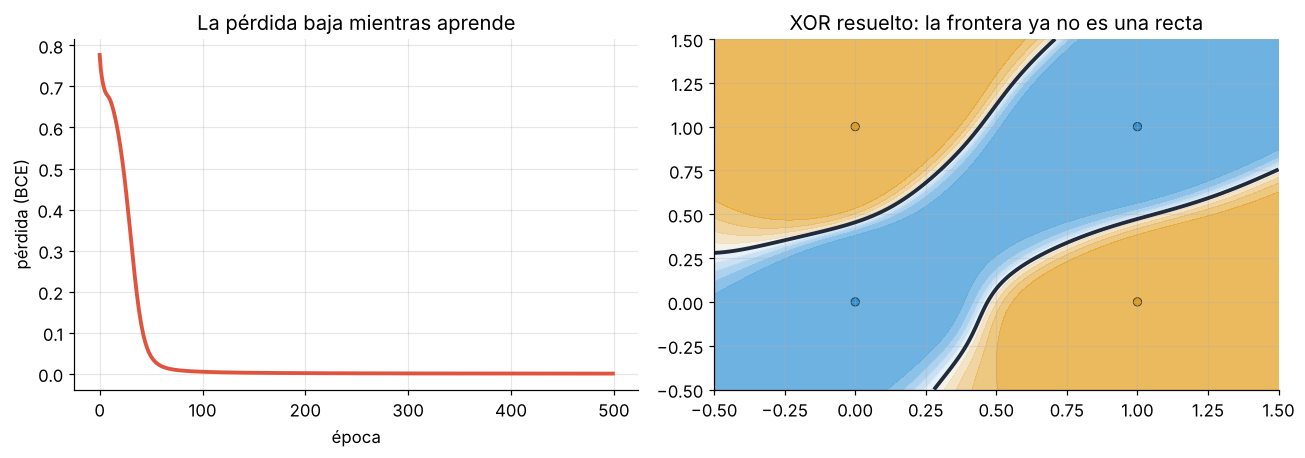

In [20]:
probs = xor_net.predict(X_xor, verbose=0).ravel()     # probabilities, one per row
clases = (probs >= 0.5).astype(int)                   # threshold 0.5 -> decision
for (s1, s2), p, c in zip(X_xor.astype(int), probs, clases):
    print(f"interruptores ({s1}, {s2}) → probabilidad {p:.2f} → luz {'encendida' if c else 'apagada'}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].plot(hist_xor.history["loss"], color=CORAL, lw=2.5)
ax[0].set_xlabel("época"); ax[0].set_ylabel("pérdida (BCE)"); ax[0].set_title("La pérdida baja mientras aprende")
plot_boundary(xor_net, X_xor, y_xor, ax[1], "XOR resuelto: la frontera ya no es una recta")
plt.tight_layout(); plt.show()

**Qué deberías ver:** probabilidades cercanas a **0, 1, 1, 0** → apagada, encendida, encendida, apagada. A la izquierda la pérdida cae; a la derecha, la zona ámbar (encendida) forma una **franja** que deja las dos esquinas apagadas en azul: dos líneas combinadas, como en la lámina 48.

### Contar parámetros sin Keras
Regla por capa: **entradas × neuronas + neuronas** (un peso por cable y un sesgo por neurona).

**Qué hace este código:**
- `contar_parametros(capas)` recibe una lista como `[2, 8, 1]` (entradas, ocultas…, salida).
- `zip(capas[:-1], capas[1:])` recorre **parejas consecutivas**: (2, 8) y (8, 1). Cada pareja es una capa: lo que entra y cuántas neuronas tiene.
- Suma `n_in * n_out + n_out` de cada capa.

🔮 **Antes de ejecutar:** la red de XOR ya la contamos (33). ¿Cuánto darán `[2, 16, 16, 1]` y `[3, 4, 1]`?

In [21]:
def contar_parametros(capas):
    # each layer: one weight per wire (n_in * n_out) plus one bias per neuron (n_out)
    return sum(n_in * n_out + n_out for n_in, n_out in zip(capas[:-1], capas[1:]))

for capas in ([2, 8, 1], [2, 16, 16, 1], [10, 8, 8, 1], [3, 4, 1]):
    print(capas, "→", contar_parametros(capas), "parámetros")
print("comprobación con Keras (red de XOR):", xor_net.count_params())

[2, 8, 1] → 33 parámetros
[2, 16, 16, 1] → 337 parámetros
[10, 8, 8, 1] → 169 parámetros
[3, 4, 1] → 21 parámetros
comprobación con Keras (red de XOR): 33


**Qué deberías ver:** 33 (XOR), **337** (la red de las lunas de la Parte F), 169 y 21; y la comprobación de Keras también en 33.

### 💭 Para pensar

**1.** En la red de XOR, ¿cuáles son los parámetros y cuáles algunos hiperparámetros?

<details><summary>Ver respuesta</summary>

Parámetros: los 33 pesos y sesgos que aprende `fit`. Hiperparámetros: 8 neuronas, `tanh`, `learning_rate=0.05`, `epochs=500`, `batch_size=4`: los eligió una persona.
</details>

**2.** ¿Por qué esta red sí resuelve XOR y el perceptrón del viernes no?

<details><summary>Ver respuesta</summary>

Porque tiene una **capa oculta con activación**: cada neurona oculta traza una línea y la salida las combina en una franja, que una sola línea no puede formar.
</details>

**3.** Después de ejecutar `predict` diez veces, ¿la red sabe más?

<details><summary>Ver respuesta</summary>

No. `predict` solo calcula hacia adelante; no toca los pesos. Solo `fit` entrena.
</details>

---
## Parte F · Keras completo: la red de las lunas
📽 Láminas 69, 71, 72, 73

**Qué vas a hacer:** el flujo completo de un proyecto real: separar datos, construir, compilar, entrenar con validación, mirar las curvas, evaluar y predecir.

### F.1 · Los datos y tres conjuntos
Usamos 600 puntos con forma de **dos lunas** (clase 1 ámbar, clase 0 azul). Los separamos como cuando estudias:
- **entrenamiento** → los ejercicios con los que estudias (la red aprende de ellos);
- **validación** → los **simulacros** que haces mientras estudias, para ver si de verdad entendiste o solo memorizaste;
- **prueba** → el **examen final**: datos que la red nunca vio, se usan una sola vez al final.

**Qué hace este código:**
- `make_moons(600, noise=0.2, ...)` fabrica 600 puntos con 2 datos cada uno; `noise` es cuánto se desordenan.
- `train_test_split(..., test_size=0.2, stratify=y_m)` aparta el **20 % = 120** puntos para la prueba, con la misma proporción de cada clase (`stratify`). Quedan **480** para entrenar.
- La gráfica muestra los puntos de entrenamiento.

🔮 **Antes de ejecutar:** ¿qué forma tendrá `X_train`?

entrenamiento: (480, 2) | prueba (examen final): (120, 2)


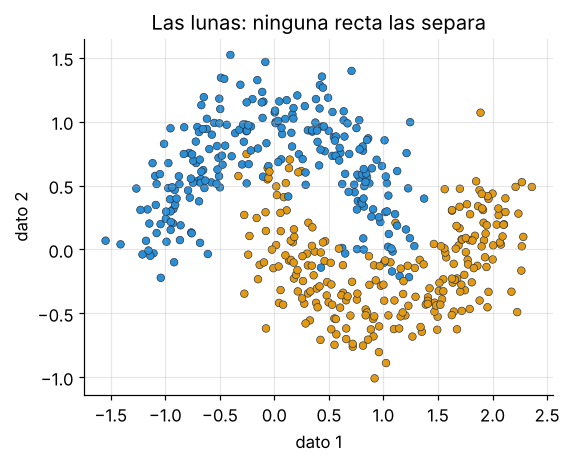

In [22]:
X_m, y_m = make_moons(600, noise=0.2, random_state=SEED)       # 600 points, 2 features
X_train, X_test, y_train, y_test = train_test_split(X_m, y_m, test_size=0.2, random_state=SEED, stratify=y_m)
print("entrenamiento:", X_train.shape, "| prueba (examen final):", X_test.shape)

plt.figure(figsize=(5.5, 4.2))
plt.scatter(*X_train.T, c=np.where(y_train == 1, AMBAR, AZUL), edgecolor=TINTA, s=25, lw=.4)
plt.title("Las lunas: ninguna recta las separa"); plt.xlabel("dato 1"); plt.ylabel("dato 2"); plt.show()

### F.2 · Construir y contar
Dos capas ocultas de 16 neuronas con **ReLU** (la válvula: la culpa llega entera hacia atrás) y una salida con sigmoide.

**Léelo así (los parámetros):** capa 1: $2\times16+16 = 48$ · capa 2: $16\times16+16 = 272$ · salida: $16\times1+1 = 17$ · **total 337**.

In [23]:
keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    keras.Input(shape=(2,)),                 # 2 input features
    layers.Dense(16, activation="relu"),     # hidden layer 1: 2*16 + 16 = 48 parameters
    layers.Dense(16, activation="relu"),     # hidden layer 2: 16*16 + 16 = 272
    layers.Dense(1, activation="sigmoid"),   # output: 16*1 + 1 = 17 -> probability of class 1
])
model.summary()
print("Total de parámetros:", model.count_params())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

Total de parámetros: 337


### F.3 · Compilar
Adam (el optimizador de la carrera, lámina 63) con `learning_rate=0.01`, la BCE como pérdida y la exactitud como métrica.

In [24]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
              loss="binary_crossentropy",
              metrics=["accuracy"])

### F.4 · Entrenar con simulacros
- `epochs=60` → 60 vueltas por los datos de entrenamiento.
- `batch_size=32` → da un paso cada 32 ejemplos (una **encuesta**, no un censo: lámina 62).
- `validation_split=0.2` → separa el 20 % del entrenamiento como **simulacros**: la red no aprende de ellos, solo se mide.

**Las cuentas de los datos:**

| Paso | Cuántos puntos |
|---|---|
| Total | 600 |
| Prueba (`test_size=0.2`) | 120 |
| Entrenamiento antes de validar | 480 |
| Validación (`validation_split=0.2`) | 96 |
| Con los que de verdad aprende | **384** |
| Pasos por época (384 ÷ 32) | **12** |
| Pasos en total (12 × 60 épocas) | **720** |

> **Ojo:** `validation_split` toma **las últimas filas** de `X_train`, sin mezclar ni equilibrar las clases. Aquí funciona porque `train_test_split` ya mezcló los datos; si tus datos vinieran ordenados (por ejemplo, todos los "sí" al final), la validación quedaría torcida.

**Qué hace este código:** entrena en silencio (`verbose=0`) y guarda el historial en `history`. `history.history` es un diccionario con una lista por medida (`loss`, `accuracy`, `val_loss`, `val_accuracy`) y un valor por época.

🔮 **Antes de ejecutar:** después de 720 pasitos, ¿qué exactitud de validación esperas: 50 %, 75 % o más de 90 %?

In [25]:
history = model.fit(X_train, y_train, epochs=60, batch_size=32, validation_split=0.2, verbose=0)

h = history.history                      # a dictionary: one list per measure, one value per epoch
print("Lo que guardó History:", list(h.keys()))
print(f"Época 60 → exactitud entrenamiento {h['accuracy'][-1]:.1%} | validación (simulacros) {h['val_accuracy'][-1]:.1%}")

Lo que guardó History: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Época 60 → exactitud entrenamiento 95.8% | validación (simulacros) 95.8%


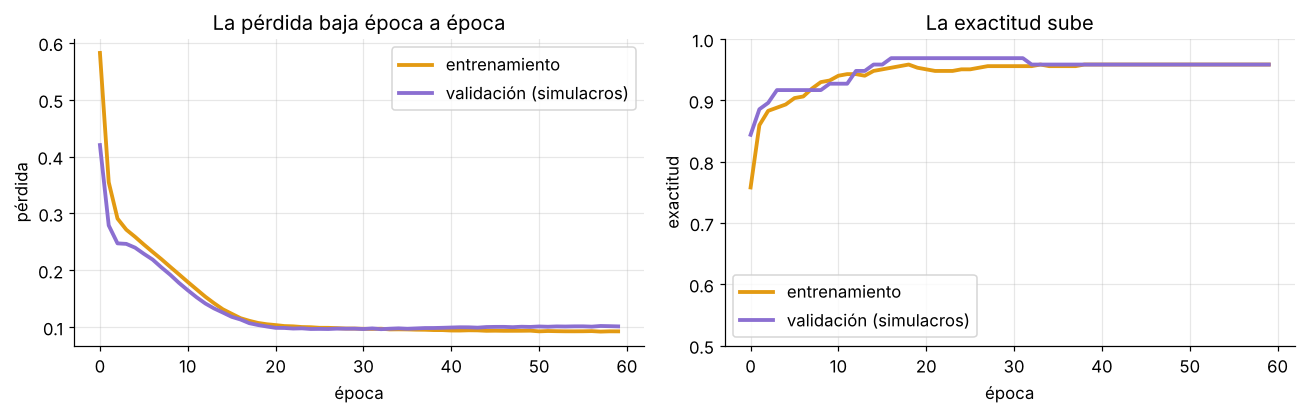

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
ax[0].plot(h["loss"], color=AMBAR, lw=2.5, label="entrenamiento")
ax[0].plot(h["val_loss"], color=LILA, lw=2.5, label="validación (simulacros)")
ax[0].set_xlabel("época"); ax[0].set_ylabel("pérdida"); ax[0].set_title("La pérdida baja época a época"); ax[0].legend()
ax[1].plot(h["accuracy"], color=AMBAR, lw=2.5, label="entrenamiento")
ax[1].plot(h["val_accuracy"], color=LILA, lw=2.5, label="validación (simulacros)")
ax[1].set_xlabel("época"); ax[1].set_ylabel("exactitud"); ax[1].set_ylim(.5, 1); ax[1].set_title("La exactitud sube"); ax[1].legend()
plt.tight_layout(); plt.show()

**Qué deberías ver:** **337 parámetros**; exactitud de validación cercana a **95 %**; y dos curvas que bajan (pérdida) y suben (exactitud) **juntas**. Si la de entrenamiento siguiera mejorando y la de validación empeorara, la red estaría **memorizando** en vez de aprender (sobreajuste: semana 3).

### F.5 · El examen final y predecir
- `model.evaluate(X, y)` → pérdida y exactitud en datos que la red **nunca vio**.
- `model.predict(X)` → la **probabilidad** de clase 1 para cada punto; con el umbral 0.5 la convertimos en decisión.
- **Ni `evaluate` ni `predict` cambian los pesos**: solo miden o preguntan. Puedes ejecutarlos cuantas veces quieras.

🔮 **Antes de ejecutar:** ¿la exactitud en el examen (prueba) será parecida a la de validación, mucho mejor o mucho peor?

Examen final (prueba): pérdida 0.131 | exactitud 95.0%
Primeros 5 del examen:
  probabilidad 0.00 → predice 0 | era 0 ✔
  probabilidad 0.01 → predice 0 | era 0 ✔
  probabilidad 0.99 → predice 1 | era 1 ✔
  probabilidad 0.04 → predice 0 | era 0 ✔
  probabilidad 1.00 → predice 1 | era 1 ✔


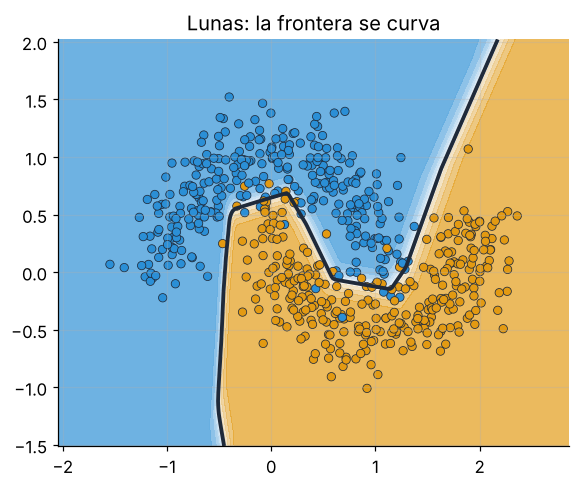

In [27]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Examen final (prueba): pérdida {test_loss:.3f} | exactitud {test_acc:.1%}")

probs_test = model.predict(X_test[:5], verbose=0).ravel()
print("Primeros 5 del examen:")
for p, c, real in zip(probs_test, (probs_test >= 0.5).astype(int), y_test[:5]):
    print(f"  probabilidad {p:.2f} → predice {c} | era {real} {'✔' if c == real else '✘'}")

fig, ax = plt.subplots(figsize=(6, 4.8))
plot_boundary(model, X_m, y_m, ax, "Lunas: la frontera se curva"); plt.show()

**Qué deberías ver:** una exactitud de prueba parecida a la de validación (≈ 95 %), las primeras predicciones casi todas con ✔ y una frontera negra curva que sigue la forma de las lunas.

### 💭 Para pensar

**1.** ¿Qué diferencia hay entre los datos de validación y los de prueba, si la red no aprende de ninguno?

<details><summary>Ver respuesta</summary>

La validación se mira **durante** el estudio (cada época) para decidir cosas, como cuántas épocas o neuronas usar. La prueba se usa **una sola vez al final**, como el examen: si la usáramos para decidir, dejaría de ser un examen justo.
</details>

**2.** De los 600 puntos, ¿con cuántos aprende de verdad la red y cuántos pasos da en total?

<details><summary>Ver respuesta</summary>

Con **384** (600 − 120 de prueba − 96 de validación). En lotes de 32 son 12 pasos por época; en 60 épocas, **720** pasos.
</details>

**3.** Si la exactitud de entrenamiento sigue subiendo y la de validación empieza a bajar, ¿qué está pasando?

<details><summary>Ver respuesta</summary>

La red está **memorizando** los ejemplos de entrenamiento en vez de aprender la regla: sobreajuste (semana 3).
</details>

---
## Parte G · ¿Qué optimizador llega primero?
📽 Lámina 63

**Qué vas a hacer:** entrenar la misma red, con los mismos pesos iniciales, usando tres optimizadores.

**La idea:** el optimizador es la **forma de caminar** cuesta abajo:
- **SGD:** el caminante. Pasos fijos en la dirección de la pendiente.
- **Momentum:** una bola que rueda (o la bicicleta en bajada): acumula impulso y no se frena en cada piedrita.
- **Adam:** zapatos a la medida de cada terreno: ajusta el paso de **cada peso** por separado.

### Ejemplo: la carrera
**Qué hace este código:**
- `make_model()` arma siempre **la misma red** (la de las lunas) y fija la semilla, para que las tres empiecen con **los mismos pesos**: una carrera justa.
- `optimizers` es un diccionario con los tres corredores. `keras.optimizers.SGD(0.05, momentum=0.9)` es SGD con impulso.
- El `for` entrena una red con cada optimizador durante 40 épocas y dibuja su pérdida de validación.
- `resultados_g` guarda la pérdida de validación final de cada uno.

🔮 **Antes de ejecutar:** ¿quién crees que termina más arriba (peor): el caminante, la bola que rueda o los zapatos a la medida?

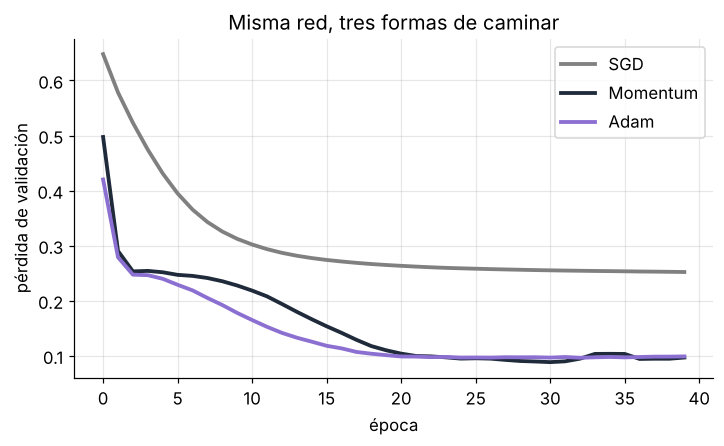

{'SGD': 0.252, 'Momentum': 0.097, 'Adam': 0.099}


In [28]:
def make_model():
    keras.utils.set_random_seed(SEED)   # same starting weights for a fair comparison
    return keras.Sequential([keras.Input(shape=(2,)), layers.Dense(16, activation="relu"),
                             layers.Dense(16, activation="relu"), layers.Dense(1, activation="sigmoid")])

optimizers = {"SGD": keras.optimizers.SGD(0.05),
              "Momentum": keras.optimizers.SGD(0.05, momentum=0.9),
              "Adam": keras.optimizers.Adam(0.01)}
colores = {"SGD": "gray", "Momentum": TINTA, "Adam": LILA}
resultados_g = {}
plt.figure(figsize=(7.5, 4))
for name, opt in optimizers.items():
    m = make_model(); m.compile(optimizer=opt, loss="binary_crossentropy")
    hh = m.fit(X_train, y_train, validation_split=0.2, epochs=40, batch_size=32, verbose=0)
    resultados_g[name] = round(hh.history["val_loss"][-1], 3)
    plt.plot(hh.history["val_loss"], lw=2.5, color=colores[name], label=name)
plt.xlabel("época"); plt.ylabel("pérdida de validación"); plt.legend(); plt.title("Misma red, tres formas de caminar"); plt.show()
print(resultados_g)

**Qué deberías ver:** SGD baja despacio y termina con la pérdida **más alta**; Momentum y Adam llegan mucho antes a una pérdida baja. Ojo, como en la lectura de tendencia: con otros `learning_rate` el orden puede cambiar. **Comparar sin ajustar a todos con el mismo cuidado es una carrera injusta.**

**Qué hace este código:** busca en `resultados_g` el optimizador con la pérdida final más alta (`max` con `key=resultados_g.get`).

In [29]:
peor_optimizador = max(resultados_g, key=resultados_g.get)    # the highest final validation loss
print("Terminó más arriba:", peor_optimizador, "| pérdidas finales:", resultados_g)

Terminó más arriba: SGD | pérdidas finales: {'SGD': 0.252, 'Momentum': 0.097, 'Adam': 0.099}


**Qué deberías ver:** `Terminó más arriba: SGD`. Sin impulso ni pasos adaptativos, avanza lento.

### 💭 Para pensar

**1.** ¿El optimizador es un parámetro o un hiperparámetro?

<details><summary>Ver respuesta</summary>

Un **hiperparámetro**: lo eliges tú antes de entrenar. La red no lo cambia.
</details>

**2.** Si SGD perdió esta carrera, ¿significa que SGD es siempre peor?

<details><summary>Ver respuesta</summary>

No. Con otro `learning_rate` o más épocas podría alcanzar a los otros. Para comparar en serio hay que ajustar a cada uno con el mismo cuidado.
</details>

---
## Resumen en 5 líneas
1. Una **capa** es `W @ x + b` y una activación; una **red** son capas en fila (forward).
2. La **pérdida** dice qué tan mal vamos; la **culpa** (la derivada de la pérdida) viaja hacia atrás con la regla de la cadena (backward) y cada peso da un paso en contra de su gradiente.
3. **TensorFlow** es el motor: calcula esas derivadas solo con `GradientTape`. **Keras** es el volante: construir → compilar → entrenar → predecir.
4. Las capas ocultas con activación permiten **fronteras curvas**: XOR, lunas y círculos.
5. Se estudia con **entrenamiento**, se mide con **validación** (simulacros) y se juzga una vez con **prueba** (el examen final).

---
## 🏁 Para comprobar que entendiste
Responde cada pregunta **antes** de abrir la respuesta. Si fallas alguna, vuelve a la parte indicada.

**Un ejemplo para mirar primero: usar el modelo con puntos nuevos.** `NUEVOS` (ya cargado) tiene 3 puntos que la red de las lunas nunca vio.

**Qué hace este código:** `model.predict(NUEVOS)` da la probabilidad de clase 1 de cada punto y `(probs_nuevos >= 0.5).astype(int)` la convierte en decisión (1 o 0). No entrena nada: el modelo ya está listo.

In [30]:
print(NUEVOS)
probs_nuevos = model.predict(NUEVOS, verbose=0).ravel()     # probabilities of class 1
clases_nuevas = (probs_nuevos >= 0.5).astype(int)           # threshold 0.5 -> decision
for punto, p, c in zip(NUEVOS, probs_nuevos, clases_nuevas):
    print(f"punto {punto} → probabilidad {p:.2f} → clase {c}")

[[ 0.    1.  ]
 [ 1.   -0.5 ]
 [ 0.5   0.25]]
punto [0. 1.] → probabilidad 0.00 → clase 0
punto [ 1.  -0.5] → probabilidad 0.99 → clase 1
punto [0.5  0.25] → probabilidad 0.25 → clase 0


**Qué deberías ver:** probabilidades ≈ **0.00, 0.99 y 0.25** → clases **0, 1, 0**. El punto (0.5, 0.25) queda en la zona azul, pero con 25 %: la red está menos segura con él porque cae cerca de la frontera.

### 💭 Preguntas

**1.** En la red 2 → 2 → 1 de la Parte A, ¿qué entra a la neurona de salida?

<details><summary>Ver respuesta</summary>

Las dos salidas de la capa oculta, $\mathbf{a}^{(1)}$, no los datos originales. (Parte A)
</details>

**2.** La red dijo 0.5569 al socio 1, que sí pagó ($y = 1$). ¿Cuál es la culpa de la salida y qué indica su signo?

<details><summary>Ver respuesta</summary>

$\delta = 0.5569 - 1 = -0.4431$: negativa, la predicción se quedó corta y hay que **subirla**. (Parte B)
</details>

**3.** ¿Qué significa en realidad «la culpa» de una neurona?

<details><summary>Ver respuesta</summary>

La **derivada** de la pérdida respecto al puntaje $z$ de esa neurona. «Culpa» es solo una metáfora. (Parte B)
</details>

**4.** Después de un paso con η = 0.5, ¿qué le pasó a la predicción y a la pérdida del socio 1?

<details><summary>Ver respuesta</summary>

La predicción subió de 0.5569 a 0.6542 (≈ 0.56 → 0.65) y la pérdida bajó de 0.5854 a 0.4243 (≈ 0.59 → 0.42). (Parte C)
</details>

**5.** ¿Qué hace `tf.GradientTape`?

<details><summary>Ver respuesta</summary>

Graba el forward y lo reproduce al revés para calcular las derivadas automáticamente (regla de la cadena). (Parte D)
</details>

**6.** ¿Cuántos parámetros tiene una red 2 → 16 → 16 → 1? Muestra la cuenta.

<details><summary>Ver respuesta</summary>

$2\cdot16+16 = 48$; $16\cdot16+16 = 272$; $16\cdot1+1 = 17$; total **337**. (Partes E y F)
</details>

**7.** ¿Cuál es la diferencia entre la sigmoide y tanh?

<details><summary>Ver respuesta</summary>

Tienen la misma forma de S, pero la sigmoide va de 0 a 1 y **tanh de −1 a 1**, centrada en 0. (Parte E)
</details>

**8.** Clasifica: `learning_rate`, un peso de la capa oculta, el número de neuronas, un sesgo, `epochs`.

<details><summary>Ver respuesta</summary>

Parámetros (los aprende la red): el peso y el sesgo. Hiperparámetros (los eliges tú): `learning_rate`, el número de neuronas y `epochs`. (Parte E)
</details>

**9.** Con 600 puntos, `test_size=0.2`, `validation_split=0.2` y `batch_size=32`, ¿cuántos pasos da la red por época?

<details><summary>Ver respuesta</summary>

600 → 480 (sin los 120 de prueba) → 384 (sin los 96 de validación); 384 ÷ 32 = **12** pasos por época. (Parte F)
</details>

**10.** ¿`model.evaluate` o `model.predict` cambian los pesos de la red?

<details><summary>Ver respuesta</summary>

No. Solo `fit` entrena; `evaluate` mide y `predict` pregunta. (Partes E y F)
</details>

---
### 🧪 Experimento 2: los círculos
📽 Lámina 74

Puntos de una clase **dentro** de un círculo y de la otra **alrededor**. Ninguna recta los separa.

**Qué hace este código:** fabrica 600 puntos con `make_circles` y aparta el 25 % (150) para validación, con la misma proporción de cada clase.

entrenamiento: (450, 2) | validación: (150, 2)


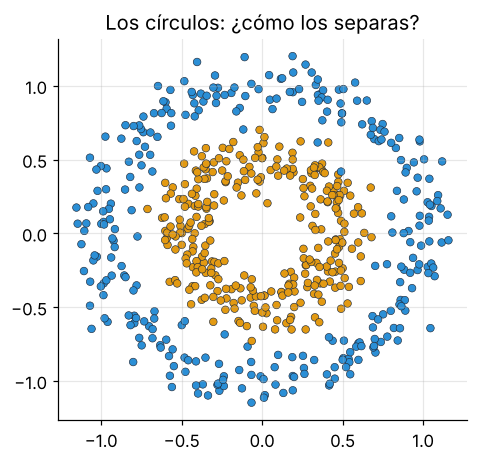

In [31]:
X_c, y_c = make_circles(600, noise=0.1, factor=0.5, random_state=SEED)   # inner circle vs outer ring
Xc_tr, Xc_va, yc_tr, yc_va = train_test_split(X_c, y_c, test_size=0.25, random_state=SEED, stratify=y_c)
print("entrenamiento:", Xc_tr.shape, "| validación:", Xc_va.shape)
plt.figure(figsize=(4.8, 4.5)); plt.scatter(*X_c.T, c=np.where(y_c == 1, AMBAR, AZUL), edgecolor=TINTA, s=25, lw=.4)
plt.title("Los círculos: ¿cómo los separas?"); plt.show()

**Primero, sin capas ocultas.** **Qué hace este código:** una red con **solo la neurona de salida** (`Dense(1, activation="sigmoid")`): es el perceptrón del viernes con sigmoide. La entrena y mide la exactitud de validación.

🔮 **Antes de ejecutar:** una sola neurona traza una sola línea. ¿Qué exactitud esperas?

In [32]:
keras.utils.set_random_seed(SEED)
sin_ocultas = keras.Sequential([keras.Input(shape=(2,)), layers.Dense(1, activation="sigmoid")])   # no hidden layer
sin_ocultas.compile(optimizer=keras.optimizers.Adam(0.01), loss="binary_crossentropy", metrics=["accuracy"])
sin_ocultas.fit(Xc_tr, yc_tr, epochs=60, batch_size=32, verbose=0)
_, acc_lineal = sin_ocultas.evaluate(Xc_va, yc_va, verbose=0)
print(f"Sin capas ocultas → exactitud de validación: {acc_lineal:.1%}")

Sin capas ocultas → exactitud de validación: 48.7%


**Qué deberías ver:** ≈ **49 %**: lo mismo que lanzar una moneda. Una recta no puede separar un círculo de un anillo.

**Ahora con capas ocultas.** **Qué hace este código:**
- `neuronas = 16` decide cuántas neuronas tiene **cada** capa oculta (es un hiperparámetro).
- Construye 2 capas ocultas con ReLU + la salida, compila con Adam y entrena 60 épocas, midiendo la validación en cada época (`validation_data`).
- Imprime los parámetros y la exactitud, y dibuja la frontera.

🔮 **Antes de ejecutar:** ¿pasará del 90 %? ¿Qué forma tendrá la frontera?

16 neuronas por capa · 337 parámetros → exactitud de validación: 98.0%


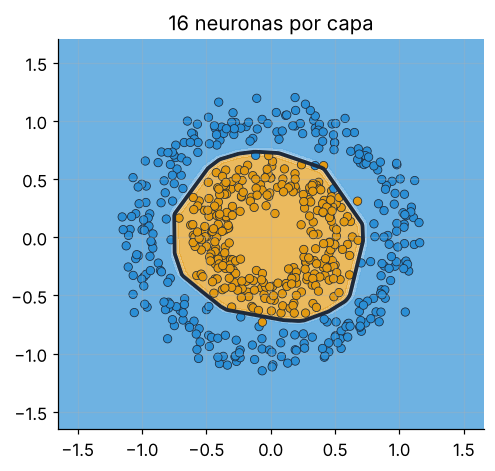

In [33]:
neuronas = 16                                   # neurons per hidden layer   (🧪 try 4, then 2)

keras.utils.set_random_seed(SEED)
modelo_circulos = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(neuronas, activation="relu"),  # hidden layer 1
    layers.Dense(neuronas, activation="relu"),  # hidden layer 2
    layers.Dense(1, activation="sigmoid"),      # output: probability of the inner circle
])
modelo_circulos.compile(optimizer=keras.optimizers.Adam(0.01), loss="binary_crossentropy", metrics=["accuracy"])
hist_c = modelo_circulos.fit(Xc_tr, yc_tr, validation_data=(Xc_va, yc_va), epochs=60, batch_size=32, verbose=0)

_, acc_c = modelo_circulos.evaluate(Xc_va, yc_va, verbose=0)
print(f"{neuronas} neuronas por capa · {modelo_circulos.count_params()} parámetros → exactitud de validación: {acc_c:.1%}")
fig, ax = plt.subplots(figsize=(5, 4.6)); plot_boundary(modelo_circulos, X_c, y_c, ax, f"{neuronas} neuronas por capa"); plt.show()

**Qué deberías ver:** **337 parámetros** y ≈ **98 %** de exactitud de validación, con una frontera negra **redonda** alrededor del círculo ámbar.

Con `neuronas = 4` quedan **37 parámetros** y ≈ **97 %**: casi igual con diez veces menos números. Con `2` (15 parámetros) baja a ≈ **79 %**: ya no le alcanzan los dobleces para cerrar el círculo.

🧪 **Experimenta:** cambia `neuronas = 16` por `4` y ejecuta otra vez; compara parámetros, exactitud y la forma de la frontera. Luego prueba `2`.

### 💭 Para pensar

**1.** ¿Por qué la red sin capas ocultas se queda cerca del 50 %?

<details><summary>Ver respuesta</summary>

Porque una sola neurona solo traza **una recta**, y ninguna recta separa un círculo de un anillo: es como adivinar.
</details>

**2.** Al pasar de 16 a 4 neuronas, ¿qué cambió: los parámetros, los hiperparámetros o ambos?

<details><summary>Ver respuesta</summary>

Cambiaste un **hiperparámetro** (neuronas por capa), y eso cambia **cuántos parámetros** hay que aprender: 337 con 16, 37 con 4.
</details>

**3.** Si con 4 neuronas también pasa del 90 %, ¿cuál red prefieres?

<details><summary>Ver respuesta</summary>

En general la más **pequeña** que funcione bien: aprende más rápido y tiene menos riesgo de memorizar. Aquí 4 neuronas (37 parámetros) dan ≈ 97 %, casi lo mismo que 16 (337). Pero hay que confirmarlo con datos de prueba.
</details>

---
**¿Te quedó alguna duda?** Repasa las slides interactivas y la guía de estudio desde la página del curso, y juega el **quiz final**.